## Create dataset and plots in 2D

Features shape: (300, 2)
Labels shape: (300,)


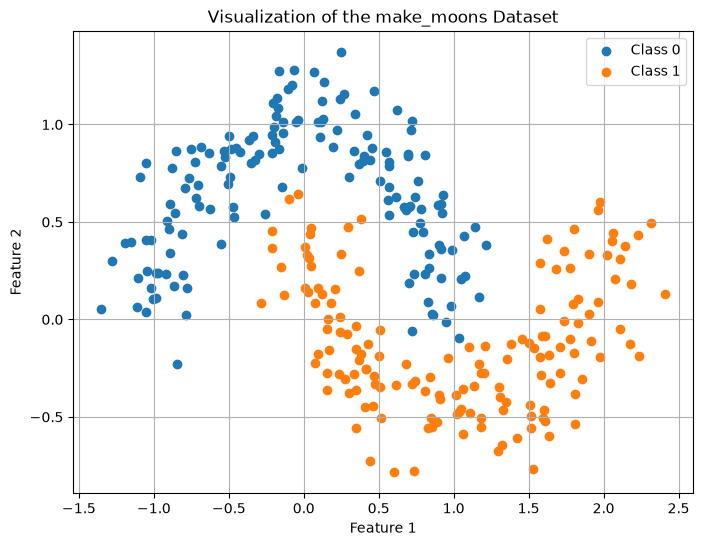

In [113]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

# Generate the dataset
X, y = make_moons(
    n_samples=300,
    noise=0.15,
    random_state=42
)

# Display the shape of the data
print("Features shape:", X.shape)
print("Labels shape:", y.shape)

# Visualize the dataset
plt.figure(figsize=(8, 6))

plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    label="Class 0"
)

plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    label="Class 1"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Visualization of the make_moons Dataset")
plt.legend()
plt.grid(True)
plt.show()

## Train/Test Separation

In [114]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (240, 2)
Testing features: (60, 2)
Training labels: (240,)
Testing labels: (60,)


## Linear SVM

In [115]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Build the Linear SVM
linear_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1.0)
)

# Train the model
linear_svm.fit(X_train, y_train)

# Predict the test labels
y_pred = linear_svm.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print(f"Linear SVM Test Accuracy: {accuracy:.2%}")

Linear SVM Test Accuracy: 80.00%


### Visualize linear kernel

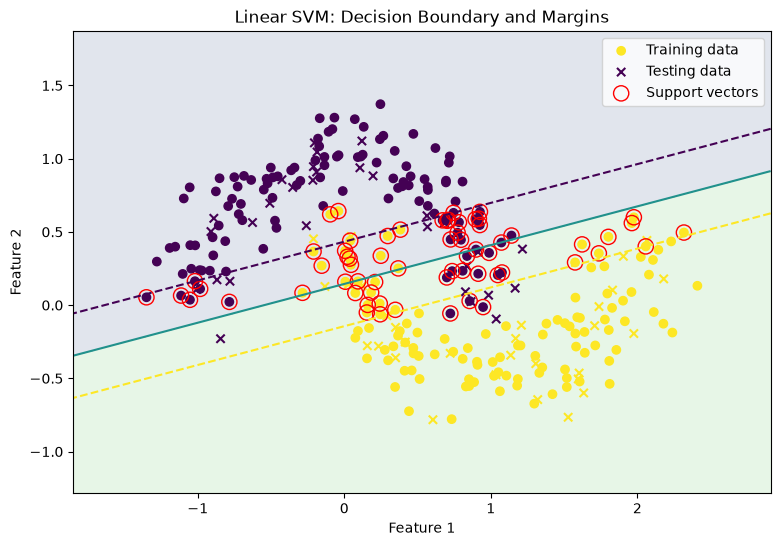

In [116]:
import numpy as np
import matplotlib.pyplot as plt

# Extract the fitted scaler and SVM
scaler = linear_svm.named_steps["standardscaler"]
svm = linear_svm.named_steps["svc"]

# Create a grid covering the feature space
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

# Convert grid coordinates into data points
grid = np.c_[xx.ravel(), yy.ravel()]

# Get the SVM decision scores
scores = svm.decision_function(scaler.transform(grid))
scores = scores.reshape(xx.shape)

# Plot the decision boundary and margins
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, scores > 0, alpha=0.15)
plt.contour(
    xx, yy, scores,
    levels=[-1, 0, 1],
    linestyles=["--", "-", "--"]
)

plt.scatter(
    X_train[:, 0], X_train[:, 1],
    c=y_train, marker="o", label="Training data"
)

plt.scatter(
    X_test[:, 0], X_test[:, 1],
    c=y_test, marker="x", label="Testing data"
)

# Highlight the support vectors
support_vectors = scaler.inverse_transform(svm.support_vectors_)

plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=120, facecolors="none", edgecolors="red",
    label="Support vectors"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Linear SVM: Decision Boundary and Margins")
plt.legend()
plt.show()

## RBF kernel train

In [127]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Create the RBF SVM model
rbf_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=1.0,
        gamma=1.0
    )
)

# Train the model
rbf_svm.fit(X_train, y_train)

# Predict the test data
y_pred_rbf = rbf_svm.predict(X_test)

# Evaluate the model
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print(f"RBF SVM Test Accuracy: {accuracy_rbf:.2%}")

RBF SVM Test Accuracy: 98.33%


In [118]:
print("Model Comparison")
print("------------------------------")
print(f"Linear SVM Accuracy: {accuracy:.2%}")
print(f"RBF SVM Accuracy:    {accuracy_rbf:.2%}")

Model Comparison
------------------------------
Linear SVM Accuracy: 80.00%
RBF SVM Accuracy:    98.33%


### Visualize RBF svm result


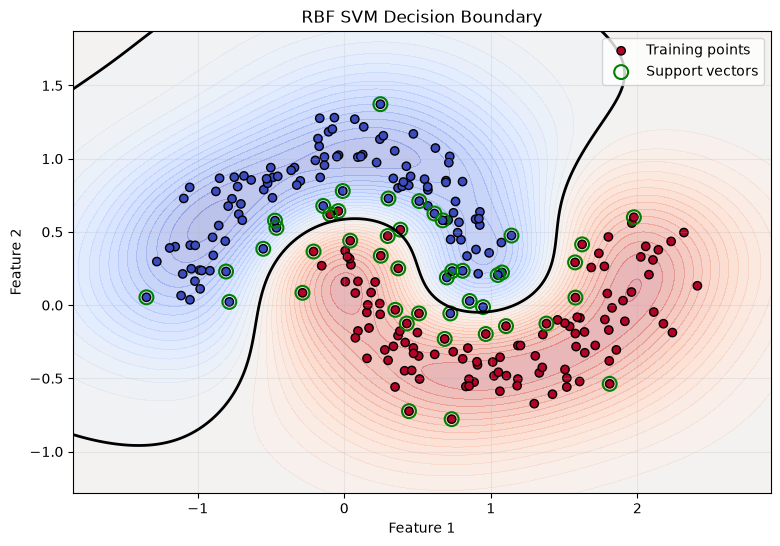

In [119]:
import numpy as np
import matplotlib.pyplot as plt

# Extract the trained scaler and SVM
scaler = rbf_svm.named_steps["standardscaler"]
svm = rbf_svm.named_steps["svc"]

# Create a grid covering the feature space
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)

# Combine grid coordinates into data points
grid = np.c_[xx.ravel(), yy.ravel()]

# Transform the grid using the same scaler used during training
grid_scaled = scaler.transform(grid)

# Calculate the decision function
Z = svm.decision_function(grid_scaled)
Z = Z.reshape(xx.shape)

# Plot the decision regions and boundary
plt.figure(figsize=(9, 6))

plt.contourf(
    xx, yy, Z,
    levels=30,
    cmap="coolwarm",
    alpha=0.35
)

plt.contour(
    xx, yy, Z,
    levels=[0],
    colors="black",
    linewidths=2
)

# Plot the training points
plt.scatter(
    X_train[:, 0], X_train[:, 1],
    c=y_train,
    cmap="coolwarm",
    edgecolors="black",
    label="Training points"
)

# Show support vectors in the original feature space
support_vectors_original = scaler.inverse_transform(
    svm.support_vectors_
)

plt.scatter(
    support_vectors_original[:, 0],
    support_vectors_original[:, 1],
    s=100,
    facecolors="none",
    edgecolors="green",
    linewidths=1.5,
    label="Support vectors"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("RBF SVM Decision Boundary")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Different gamma values - for RBF

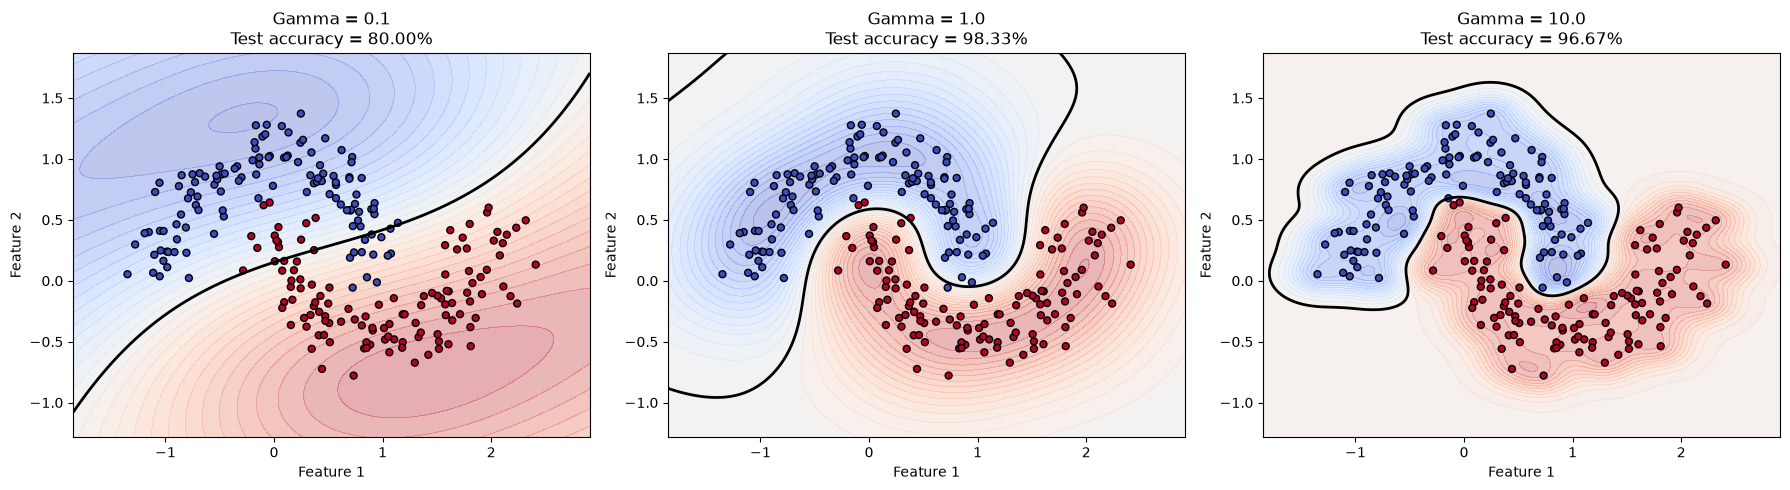

In [120]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Try three different gamma values
gamma_values = [0.1, 1.0, 10.0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, gamma in zip(axes, gamma_values):

    # Create and train the RBF SVM
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, gamma=gamma)
    )

    model.fit(X_train, y_train)

    # Evaluate on the same test set
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    # Create a grid for the decision boundary
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    # Calculate decision scores through the complete pipeline
    scores = model.decision_function(grid).reshape(xx.shape)

    # Draw decision regions and the decision boundary
    ax.contourf(
        xx, yy, scores,
        levels=30,
        cmap="coolwarm",
        alpha=0.35
    )

    ax.contour(
        xx, yy, scores,
        levels=[0],
        colors="black",
        linewidths=2
    )

    # Plot training points
    ax.scatter(
        X_train[:, 0],
        X_train[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    ax.set_title(
        f"Gamma = {gamma}\nTest accuracy = {accuracy:.2%}"
    )
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

### different C values

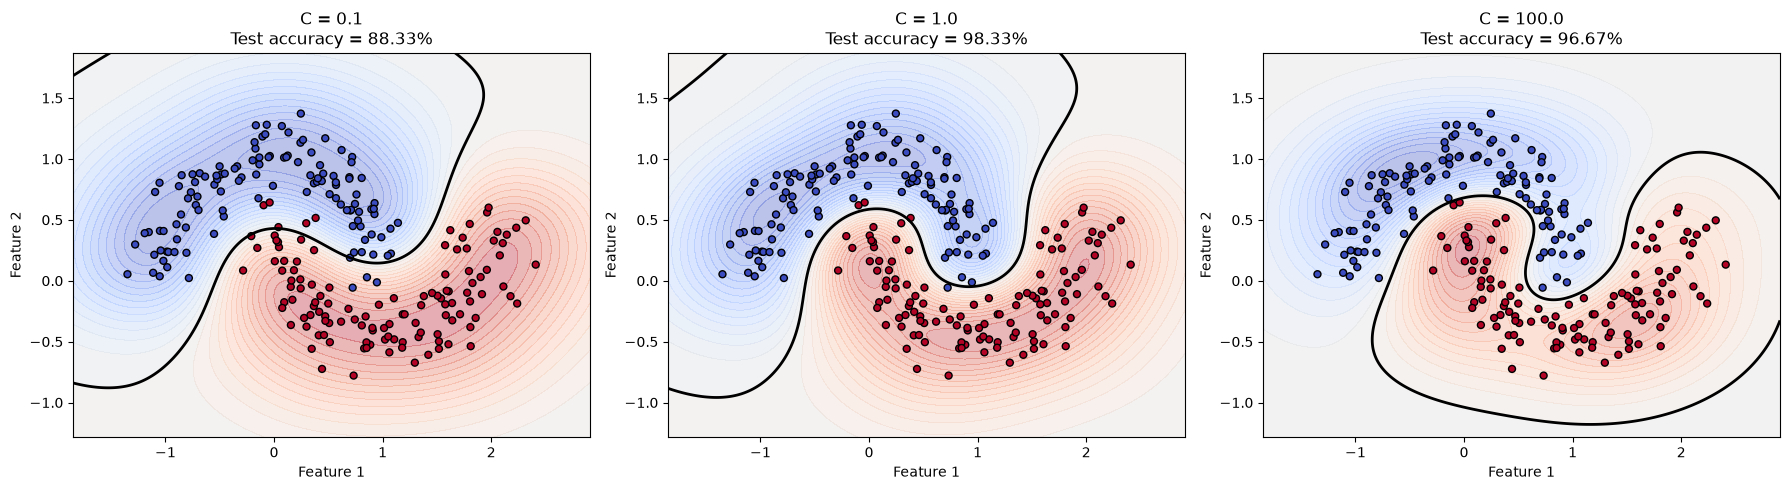

In [121]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

C_values = [0.1, 1.0, 100.0]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, C in zip(axes, C_values):
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=C, gamma=1.0)
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model.decision_function(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, scores,
        levels=30,
        cmap="coolwarm",
        alpha=0.35
    )

    ax.contour(
        xx, yy, scores,
        levels=[0],
        colors="black",
        linewidths=2
    )

    ax.scatter(
        X_train[:, 0], X_train[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    ax.set_title(f"C = {C}\nTest accuracy = {accuracy:.2%}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

## Polynomial Kernel


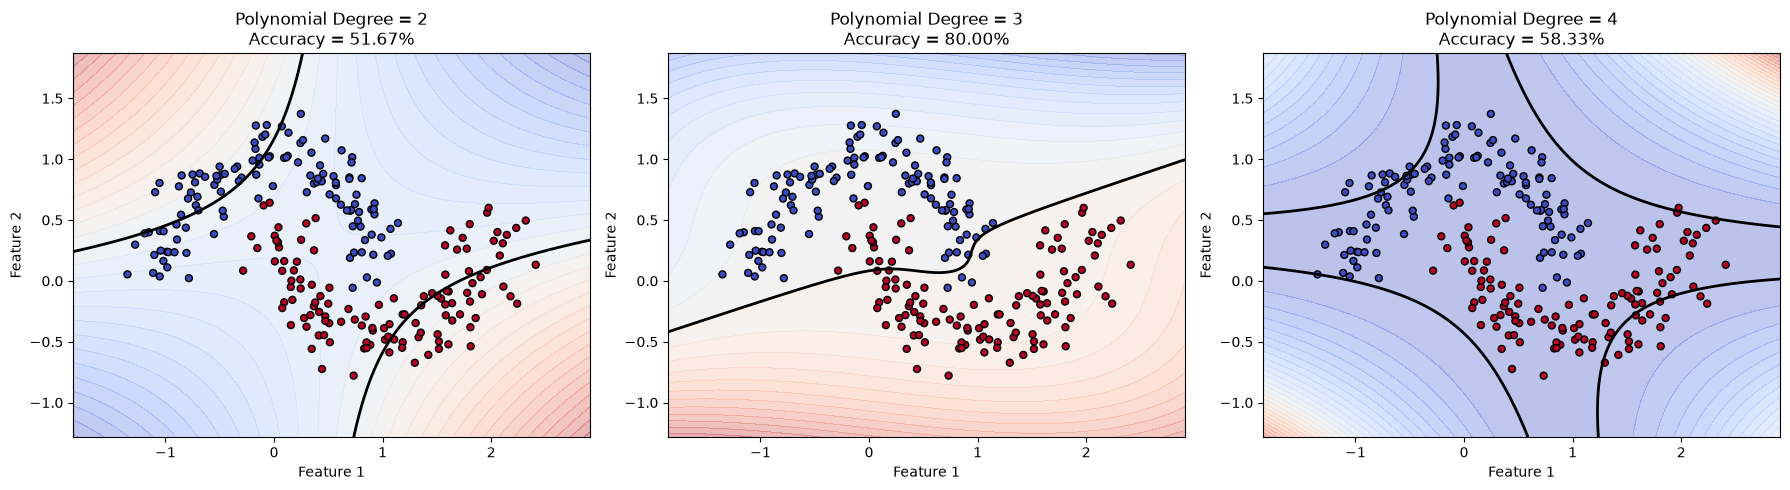

In [122]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

degrees = [2, 3, 4]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, degree in zip(axes, degrees):

    # Create the Polynomial SVM
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="poly", degree=degree, C=1.0)
    )

    # Train the model
    model.fit(X_train, y_train)

    # Test the model
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    # Create a grid for drawing the decision boundary
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model.decision_function(grid).reshape(xx.shape)

    # Draw the decision regions
    ax.contourf(
        xx, yy, scores,
        levels=30,
        cmap="coolwarm",
        alpha=0.35
    )

    # Draw the decision boundary
    ax.contour(
        xx, yy, scores,
        levels=[0],
        colors="black",
        linewidths=2
    )

    # Draw the training data
    ax.scatter(
        X_train[:, 0], X_train[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="black",
        s=25
    )

    ax.set_title(f"Polynomial Degree = {degree}\nAccuracy = {accuracy:.2%}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

### Different C values for polynomial


In [123]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

C_values = [0.1, 1.0, 100.0]

for C in C_values:
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="poly", degree=3, C=C)
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"C = {C}: Accuracy = {accuracy:.2%}")

C = 0.1: Accuracy = 81.67%
C = 1.0: Accuracy = 80.00%
C = 100.0: Accuracy = 83.33%


### Different C values for Linear kernel

In [124]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

C_values = [0.1, 1.0, 100.0]

for C in C_values:
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="linear", C=C)
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"C = {C}: Accuracy = {accuracy:.2%}")

C = 0.1: Accuracy = 78.33%
C = 1.0: Accuracy = 80.00%
C = 100.0: Accuracy = 80.00%


### RBF kernel

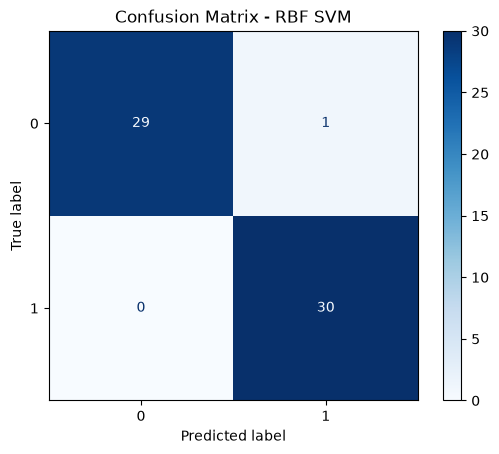

In [125]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma=1.0)
)

best_model.fit(X_train, y_train)

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    cmap="Blues"
)

plt.title("Confusion Matrix - RBF SVM")
plt.show()

In [126]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Linear SVM": SVC(kernel="linear", C=1.0),

    "Polynomial SVM": SVC(
        kernel="poly",
        degree=3,
        C=100.0
    ),

    "RBF SVM": SVC(
        kernel="rbf",
        C=1.0,
        gamma=1.0
    )
}

results = []

for name, svm in models.items():

    model = make_pipeline(
        StandardScaler(),
        svm
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

         Model  Accuracy  Precision  Recall  F1-score
    Linear SVM    0.8000     0.7500  0.9000    0.8182
Polynomial SVM    0.8333     0.7632  0.9667    0.8529
       RBF SVM    0.9833     0.9677  1.0000    0.9836
